📌 Данная практическая работа посвящена освоению методов работы с химическими структурами и их предобработке для последующего анализа. В рамках практической работы студенту предстоит:

*   Поиск, удаление пропусков → минимизировать ошибки при расчётах;


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Установка библиотки RDkit
! pip install rdkit --quiet

📌 RDkit - коллекция модулей для хемоинформатики и машинного обучения https://github.com/rdkit/rdkit  
<img src="https://www.knime.com/sites/default/files/styles/inline_small/public/rdkit_logo.png?itok=K0" width="150">,  
Документация https://rdkit.readthedocs.io/_/downloads/en/latest/pdf/


**Ключевые модули/подмодули библиотеки RDKit:**

*   **Chem** - модуль основных инструменты для работы с химией (“A module for molecules and stuff”)
*   **Chem.AllChem** - подмодуль специализированных/менее распространенных инструментов
*   **Chem.Descriptors** - подмодуль инструментов для работы с дескрипторами
*   **Chem.Draw** - подмодуль инструментов для визуализации
*   **ML** - модуль инструментов для машинного обучения








#⚡ **1 Форматы данных**

##✔️ 1.1 SMILES

Что такое SMILES?

>📌  Simplified Molecular Input Line Entry System (SMILES) — это простая, компактная система обозначения молекул.

*   Атомы: в виде их символов **C,N,O,S,F,C** или со скобками **[Au], [Ag], [Se]**
*   Связи: одинарные не указываются, двойные "**=**", тройные "**#**"

In [ ]:
# Импорт модулей
from rdkit import Chem # основной модуль для базовых функций (чтение SMILES, создание mol, расчет дескрипторов и т.д.)
from rdkit.Chem.Draw import IPythonConsole # для настройки визуализации
from rdkit.Chem import rdDepictor # для генерации 2D-координат молекул

# Настройка изображений
IPythonConsole.ipython_useSVG = True # векторная графика
IPythonConsole.molSize = 300, 300 # размер
rdDepictor.SetPreferCoordGen(True) # алгоритм генерации координат

📌  Объект mol (Molecule) в RDKit - это основной программный объект, который представляет молекулу в оперативной памяти, объект класса rdkit.Chem.rdchem.Mol.

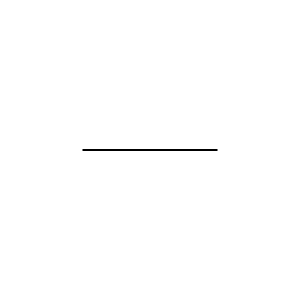

In [ ]:
ethan = Chem.MolFromSmiles("CC") # MolFromSmiles() - функция, которая преобразует SMILES-строку в молекулярный объект (Mol object)
ethan

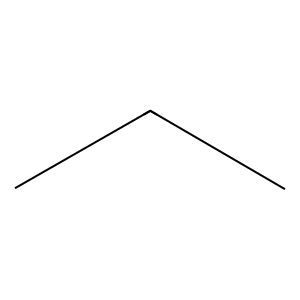

In [ ]:
Chem.MolFromSmiles("CCC")

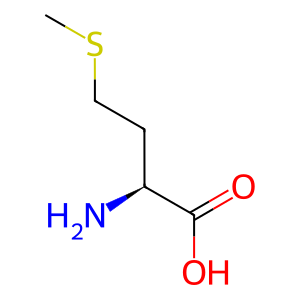

In [ ]:
methionine	= Chem.MolFromSmiles("CSCC[C@@H](C(=O)O)N")
methionine

In [ ]:
# Задаем переменные для молекул
ethylene = Chem .MolFromSmiles("C=C") # CH2=CH2
acetylene = Chem.MolFromSmiles("C#C") # CH≡CH
ethanol = Chem.MolFromSmiles("CCO") # CH3-CH2-OH
ethylenamine = Chem.MolFromSmiles("CC[NH3+]") # CH3-CH2-NH3+
acetate_salt = Chem.MolFromSmiles("CC(=O)[O-].[Na+]") # CH3-C00-Na
cycle = Chem.MolFromSmiles("C1CCCCC1C2CCCCO2") # Цикл
arenes = Chem.MolFromSmiles("c1ccccc1") # бензол

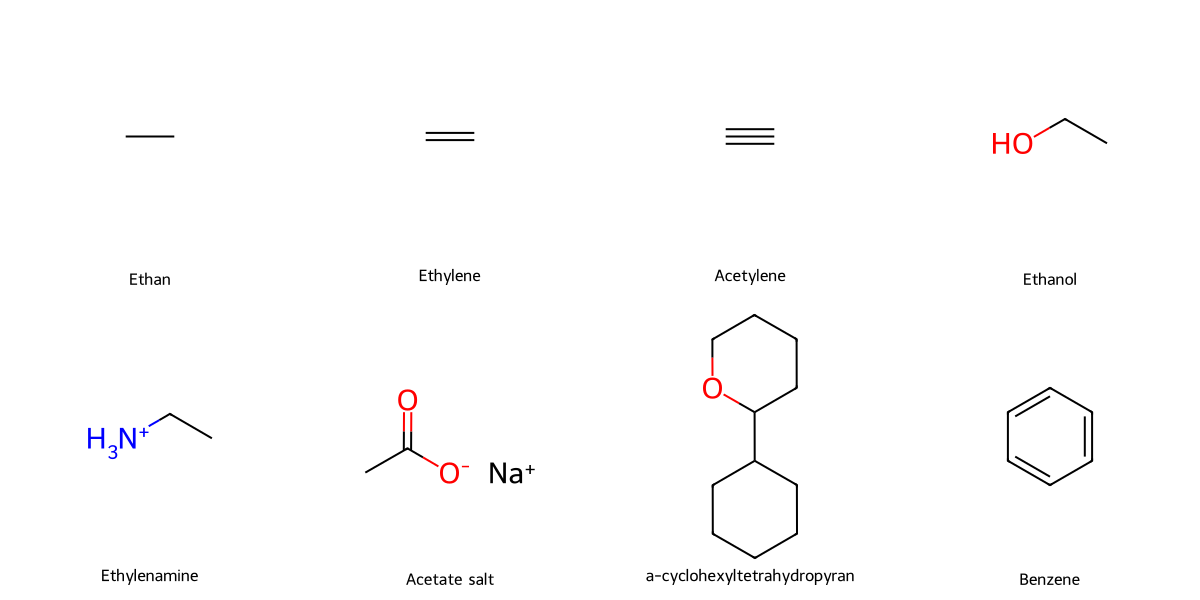

In [ ]:
# Визулизация молекул
from rdkit.Chem import Draw # подмодуль RDKit, который содержит функции для визуализации молекул.

mols = [ethan, ethylene, acetylene, ethanol, ethylenamine, acetate_salt, cycle, arenes] # список переменных
legends = ['Ethan', 'Ethylene', 'Acetylene', 'Ethanol', 'Ethylenamine', 'Acetate salt', 'a-cyclohexyltetrahydropyran' , 'Benzene'] # подпись

img = Draw.MolsToGridImage(
    mols,
    molsPerRow=4,
    subImgSize=IPythonConsole.molSize,
    legends=legends,
)
display(img)

### Канонические SMILES

In [ ]:
# Импорт модулей

import pandas as pd # модуль работы с датафреймами
from rdkit.Chem import PandasTools # pandas "для работы с молекулами в датафрейме"

In [ ]:
# Создаем датасет из 5 молекул этанола с разными SMILES

smiles_variants = [
    "CCO",           # обычная запись
    "OCC",           # начинаем с кислорода
    "C(C)O",         # со скобками
    "[CH3][CH2][OH]", # явные атомы
    "C-C-O",           # указываем связи
]

df = pd.DataFrame(smiles_variants, columns=['SMILES']) # создаем датафрейм

df['Structure'] = [Chem.MolFromSmiles(s) for s in df['SMILES']] # добавляем столбцец "Structure" с mol для отображения структур молекул
PandasTools.RenderImagesInAllDataFrames(images=False) # режим отображения структу
df

,SMILES,Structure
0,CCO,<rdkit.Chem.rdchem.Mol object at 0x7f4eaa962a40>
1,OCC,<rdkit.Chem.rdchem.Mol object at 0x7f4eaa962ab0>
2,C(C)O,<rdkit.Chem.rdchem.Mol object at 0x7f4eaa962b20>
3,[CH3][CH2][OH],<rdkit.Chem.rdchem.Mol object at 0x7f4eaa962b90>
4,C-C-O,<rdkit.Chem.rdchem.Mol object at 0x7f4eaa962c00>


In [ ]:
# Поиск дуплиатов
print("Количество дупликатов: ", df.duplicated("SMILES").sum())

Количество дупликатов:  0


📌  Канонические SMILES (Canonical SMILES) — это стандартизированная версия строк SMILES, которая позволяет однозначно представить химическую структуру.

In [ ]:
# Добавлем столбец с каноническими SMILES
df['canonical_SMILES'] = df['Structure'].apply(Chem.MolToSmiles)

df.head()

,SMILES,Structure,canonical_SMILES
0,CCO,<rdkit.Chem.rdchem.Mol object at 0x7f4eaa962a40>,CCO
1,OCC,<rdkit.Chem.rdchem.Mol object at 0x7f4eaa962ab0>,CCO
2,C(C)O,<rdkit.Chem.rdchem.Mol object at 0x7f4eaa962b20>,CCO
3,[CH3][CH2][OH],<rdkit.Chem.rdchem.Mol object at 0x7f4eaa962b90>,CCO
4,C-C-O,<rdkit.Chem.rdchem.Mol object at 0x7f4eaa962c00>,CCO


In [ ]:
# Поиск дуплиатов
print("Количество дупликатов: ", df.duplicated("canonical_SMILES").sum())

Количество дупликатов:  4


### Изомеры и таутомеры

In [ ]:
# Пример изомеров: бутан и изобутан
butene_1 = Chem.MolFromSmiles("C=C-C-C")
bune_2 = Chem.MolFromSmiles("C-C=C-C")

isomers = [butene_1, butene_2]
names = ['Butene-1', 'Butene-2']

img = Draw.MolsToGridImage(
    isomers,
    molsPerRow=2,
    subImgSize=IPythonConsole.molSize,
    legends=names,
    useSVG=IPythoonsole.ipython_useSVG
)
display(img)

print('Канонические SMILES: ')
for mol in isomers:
    print( Chem.MolToSmiles(mol))

NameError: name 'butene_2' is not defined

In [ ]:
# Пример кето‑енольной таутомерии
keton = Chem.MolFromSmiles("CC(=O)CC(=O)OC")
enol = Chem.MolFromSmiles("C=C(O)C(=O)OC")

tautomers = [keton, enol]
names = ['Keton', 'Enol']

img = Draw.MolsToGridImage(
    tautomers,
    molsPerRow=2,
    subImgSize=IPythonConsole.molSize,
    legends=names,
    useSVG=IPythonConsole.ipython_useSVG
)
display(img)

print('Канонические SMILES: ')
for mol in tautomers:
    print( Chem.MolToSmiles(mol))

##✔️ 1.2 SMARTS

Что такое SMARTS?

📌 SMILES arbitrary target specification (SMARTS) — язык для сопоставления и поиска молекулярных подструктур.

In [ ]:
curcumin = Chem.MolFromSmiles('COc1cc(/C=C/C(=O)CC(=O)/C=C/c2ccc(O)c(OC)c2)ccc1O') # Структура куркумина
curcumin

In [ ]:
# Поиск подструктуры: α,β-ненасыщенные карбонилы
smarts_curcumin = Chem.MolFromSmarts("[C]=[C][C](=[O])[C]") # SMARTS
curcumin.GetSubstructMatch(smarts_curcumin) # функция, которая ищет перрвое совпадение
curcumin

В чем отличие SMILES и SMARTS?

In [ ]:
# Задаем подструктуру метилбензола (SMARTS по SMILES)
methyl_benzene_smarts = Chem.MolFromSmarts("c1ccccc1C")
methyl_benzene_smarts = Chem.MolFromSmarts("c1ccccc1[#6]")
methyl_benzene_smarts

In [ ]:
# Задаем структуру этилбензола
ethyl_benzene = Chem.MolFromSmiles("c1ccccc1CC")
ethyl_benzene

In [ ]:
# Поиск подструктуры метилбензола в структуре этилбензола
ethyl_benzene.GetSubstructMatch(methyl_benzene_smarts)

if ethyl_benzene.HasSubstructMatch(methyl_benzene_smarts) == True:
  print ("Совпадение найдено")
  display(ethyl_benzene)
else:
  print ("Совпадений не найдено")

In [ ]:
# Задаем подструктуру дифенилбензола

biphenyl = Chem.MolFromSmiles("c1ccccc1c2ccccc2")
biphenyl

In [ ]:
# Поиск подструктуры метилбензола в структуре дифенилбензола
biphenyl.GetSubstructMatch(methyl_benzene_smarts)

if biphenyl.HasSubstructMatch(methyl_benzene_smarts) == True:
  print ("Совпадение найдено")
  display(biphenyl)
else:
  print ("Совпадений не найдено")

**Некоторые правила SMARTS**

https://www.daylight.com/dayhtml/doc/theory/theory.smarts.html

<img src="https://raw.githubusercontent.com/OlgaOVolkova/Biochemistry_26-27_Practice/main/images/smarts.png" width="500">

📌Отличие SMARTS от SMILES: SMILES описывает конкретную молекулу, SMARTS	описывает паттерн для поиска.

#⚡ **2 Источники данных**

📌Откуда можно взять данные?  

*   Получить экспериментально 🧪
*   Найти данные/готовые датасеты из статей 📉
*   Загрузить из открытых БД 🖥️
*   Приобрести коммерческие наборы 💰



In [ ]:
# Адресс файла 'IC50_practice.csv'https://raw.githubusercontent.com/OlgaOVolkova/Biochemistry_26-27_Practice/main/data/IC50.csv
url = ""

# Загрузка файла 'IC50_practice.csv' в виде датафрейма
df_git = pd.read_csv(url)

print('Кол-во строк: ', len(df_git))
df_git.head()

In [ ]:
# Адресс файла 'IC50_practice.csv'https://raw.githubusercontent.com/OlgaOVolkova/Biochemistry_26-27_Practice/main/data/IC50.csv
url = ""

# Загрузка файла 'IC50_practice.csv' в виде датафрейма
df_git = pd.read_csv(url)

print('Кол-во строк: ', len(df_git))
df_git.head()

In [ ]:
# Адресс файла 'IC50_practice.csv'https://raw.githubusercontent.com/OlgaOVolkova/Biochemistry_26-27_Practice/main/data/IC50.csv
url = ""

# Загрузка файла 'IC50_practice.csv' в виде датафрейма
df_git = pd.read_csv(url)

print('Кол-во строк: ', len(df_git))
df_git.head()

Что такое API?

>📌  Application programming interface (API) — это программный интерфейс приложений, набор инструкций, который позволяет разным приложениям общаться между собой.


In [ ]:
import requests # импорт библиотеки requests для отправки HTTP-запросов

<img src="https://raw.githubusercontent.com/OlgaOVolkova/Biochemistry_26-27_Practice/main/images/PubChem_ChEMBL_PDB.png" width="800">

📌Реляционная база данных — это тип базы данных, в котором данные организованы в виде связанных таблиц (отношений).
<img src="https://raw.githubusercontent.com/OlgaOVolkova/Biochemistry_26-27_Practice/main/images/Relational_DB.png" width="800">

## ✔️ 2.1 PubChem

📌 PubChem — открытая БД химических соединений (> 100 млн compound). https://pubchem.ncbi.nlm.nih.gov/  

<img src='https://pubchem.ncbi.nlm.nih.gov/pcfe/docs/images/tutorial-1.png' width="1000">

**Запрос к PubChem:**  
<img src="https://raw.githubusercontent.com/OlgaOVolkova/Biochemistry_26-27_Practice/main/images/PubChem_API.png" width="800">

In [ ]:
# Найдем CID соединения аспирин по названию

# Задаем переменную name - название соединения
name = "aspirin"

# Задаем переменную url - адрес сервера
url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{name}/cids/JSON"

# Задаем переменную r - ответ сервера
r = requests.get(url)

# Проверка ошибок запроса
r.raise_for_status()

# Задаем переменную response - словарь из данных ответа
response = r.json()

# Проверка наличия CID
if "IdentifierList" in response:
    cid = response["IdentifierList"]["CID"][0]
else:
    raise ValueError(f"Нет данных CID: {name}")
print(f"PubChem CID соединения {name}:\n{cid}")

In [ ]:
# Найдем молекулярную массу соединения аспирин по CID

url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid}/property/MolecularWeight/JSON"


r = requests.get(url)
r.raise_for_status()
response = r.json()

if "PropertyTable" in response:
    mol_weight = response["PropertyTable"]["Properties"][0]["MolecularWeight"]
else:
    raise ValueError(f"Нет совпадений по CID: {cid}")
print(f"Молекулярная масса соединения {name} составляет:\n{mol_weight}")

In [ ]:
# Найдем изображение струкктуры соединения аспирин

from IPython.display import Image, display # для визуализации

url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid}/PNG"

r = requests.get(url)
r.raise_for_status()

print("2D структра аспирина:")
display(Image(r.content))

In [ ]:
# Найдем CID соединения по SMILES CC(CCCCC=C)CCC/C=C\C#CCC[C@@H](C(=O)[O-])OC.[Na+]

#compound_smiles = "CC(=O)OC1=CC=CC=C1C(=O)O"
compound_smiles = "CC(CCCCC=C)CCC/C=C\C#CCC[C@@H](C(=O)[O-])OC.[Na+]"
url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/smiles/{compound_smiles}/cids/JSON"


r = requests.get(url)
r.raise_for_status()
response = r.json()

# Проверка наличия CID
if "IdentifierList" in response:
    cid = response["IdentifierList"]["CID"][0]
else:
    raise ValueError(f"Нет данных CID: {name}")
print(f"PubChem CID соединения {name}:\n{cid}")

<>:4: SyntaxWarning: invalid escape sequence '\C'
<>:4: SyntaxWarning: invalid escape sequence '\C'
/tmp/ipykernel_1163/2561886285.py:4: SyntaxWarning: invalid escape sequence '\C'
  compound_smiles = "CC(CCCCC=C)CCC/C=C\C#CCC[C@@H](C(=O)[O-])OC.[Na+]"


NameError: name 'requests' is not defined

In [ ]:
Chem.MolFromSmiles(compound_smiles)

In [ ]:
! pip install pubchempy --quiet # - библиотека для взаимодействия с базой данных PubChem на языке Python через PUG REST API

In [ ]:
import pubchempy as pcp
from pubchempy import Compound, get_compounds # импорт модулей

**Документация по Pubchempy**  
https://pubchempy.readthedocs.io/_/downloads/en/stable/pdf/

In [ ]:
# Поиск CID по SMILES с использованием библиотеки pubchempy

pcp.get_compounds("CC(CCCCC=C)CCC/C=C\C#CCC[C@@H](C(=O)[O-])OC.[Na+]", "smiles")

In [ ]:
compound = Compound.from_cid(2244) # объект compound со всеми свойствами соединения с CID 2244
print(compound.molecular_formula)
cs = get_compounds("Aspirin", "name") # объект cs со всеми свойствами соединения со значением Aspirin в name
print(cs[0].molecular_weight)

In [ ]:
# Поиск нескольких соединений и составление датафрейма

cid_list = [2244, 3672, 5288]  # список CID (Аспирин, Парацетамол, Ибупрофен)
compounds = [pcp.Compound.from_cid(cid) for cid in cid_list] # список объектов

# # преобразование объектов в датафрейм
df_compounds = pcp.compounds_to_frame(
    compounds,
    properties=['cid', 'iupac_name', 'molecular_formula', 'molecular_weight', 'canonical_smiles']
)


df_compounds.head()

In [ ]:
print(df_compounds.columns)

In [ ]:
# Поиск соединений, структурно похожих на аспирин

similar_compounds = pcp.get_compounds(
    2244, # каую запись ищем
    namespace='cid', # где ищем запись
    searchtype='similarity', # тип поиска - по подобию
    Threshold=90, # порог подобия в 90%
    MaxRecords=5 # ограничения на кол-во записей
)

In [ ]:
df_compounds = pcp.compounds_to_frame(
    similar_compounds,
    properties=['cid', 'canonical_smiles', 'inchikey']
)

df_compounds.head(5)

## ✔️ 2.2 ChEMBL

📌ChEMBL — это крупная открытая база данных биоактивных молекул с информацией о свойствах, активностях, мишенях, патентах и т.д. https://www.ebi.ac.uk/chembl/

In [ ]:
# Установка Python-пакета ChEMBL WebResource Client — официальной библиотеки для взаимодействия с ChEMBL API

! pip install chembl_webresource_client --quiet

In [ ]:
# Импорт модулей

from chembl_webresource_client.new_client import new_client # new_client - объект ("фабрика"), который создает определенный тип объектов

Поиск по свойствам соединений

In [ ]:
# Фильтр ChEMBL по условиям (фазы испытаний (max_phase), типу молекулы (molecule_type) и природы соединений (органические/неорганические))

molecule = new_client.molecule          # Подключение к ChEMBL

# Фильтр ChEMBL по условиям (фазы испытаний (max_phase), типу молекулы (molecule_type) и природы соединений (органические/неорганические))
molecule_filter = molecule.filter(
    max_phase=4,                        # Одобренные препараты (фаза 4)
    molecule_type='Small molecule',     # Только малые молекулы
    inorganic_flag=0                    # Исключение неорганических соединений
)

In [ ]:
# Создание датафрейма на основе фильтра

df_molecule = pd.DataFrame(list(molecule_filter))  # Преобразуем фильтр в список для создания DataFrame

print('Кол-во строк: ', len(df_molecule.axes[0]))
print('Кол-во столбов: ', len(df_molecule.axes[1]))
df_molecule.head(5)

In [ ]:
print(df_molecule.columns)

# 1. Основные идентификаторы и классификации:
# molecule_chembl_id - Уникальный идентификатор молекулы (CheMBL)
# pref_name - Основное название молекулы
# molecule_type - Тип молекулы: Small molecule, Antibody, Oligonucleotide, Protein
# atc_classifications - международная классификация лекарств (Anatomical Therapeutic Chemical (ATC)

# 2. свойства молекулы:
# natural_product - является ли соединение природным (да, нет)

# 3. Клинические данные:
# max_phase - фаза клинических испытаний (0-4)

# 4. Пути введения и формы:
# 'oral' - перорально, 'parenteral' - иньекционно, 'topical' - наружно

# 5. Структурные данные:
# molecule_structures - структурные данные (SMILES, InChIKey, молекулярная формула)

# 6. Дополнительные ссылки и синонимы
# 7. Биотерапевтические молекулы

In [ ]:
# убираем лишние столбцы, оставляем 'molecule_chembl_id', 'molecule_structures'

df_molecule = df_molecule[['molecule_chembl_id', 'molecule_structures']]
print('Кол-во строк: ', len(df_molecule.axes[0]))
print('Кол-во столбов: ', len(df_molecule.axes[1]))
df_molecule.head()

In [ ]:
# Выведем ячейку из первой строки второго столбца "molecule_structures"

print(df_molecule.iloc[0, 1])

# Значения в столбце molecule_structures является словарем, который состоит из ключей и значений:
# Ключи (canonical_smiles, standard_inchi и т.д.) - структурные дескрипторы

In [ ]:
# Выделим значения "canonical_smiles" из каждой записи

df_molecule = df_molecule.dropna(subset=['molecule_structures']) # удаляем пустые ячейки
df_molecule['canonical_smiles'] = df_molecule['molecule_structures'].apply( # задаем новый столбец 'canonical_smiles' со значениями "canonical_smiles"
    lambda x: x.get('canonical_smiles') if isinstance(x, dict) else None
)
df_molecule = df_molecule.drop(columns=['molecule_structures'])
print('Кол-во строк: ', len(df_molecule))
df_molecule.head(2)

In [ ]:
# Сохраняем датасет df_molecule в файл practise_1_result.csv

df_molecule.to_csv('practise_1_result.csv', sep=',', index=False)

Поиск по белку-мишени

In [ ]:
# Составляем запрос к target БД ChEMBL, чтобы найти идентифиатор белка

target = new_client.target # запрос по белку
target_query = target.search('EGFR') # поиск данных по запросу "EGRF" (рецептор эпидермального фактора роста)
kinase = pd.DataFrame.from_dict(target_query) # создание датафрейма на основе запроса "target_query"
kinase.head(10) # вывод строк датафрейма (первые 50 строк)

In [ ]:
# Составляем запрос к activity БД ChEMBL (поиск записией об аффинности к белку CHEMBL3714704)

selected_target = 'CHEMBL203'
activity = new_client.activity
res = activity.filter(target_chembl_id=selected_target).filter(type='IC50') # Тип аффинности IC_50
activity_df = pd.DataFrame.from_dict(res)
print("Кол-во строк: ", len (activity_df))
activity_df.head()

In [ ]:
# Формируем датасет на основе запроса activity

df_IC50 = activity_df[[   # Выбраем столбцы
    'molecule_chembl_id',
    'canonical_smiles',
    'standard_value',
    'standard_units',
]]
df_IC50
df_IC50 = df_IC50.rename(columns={'canonical_smiles': 'SMILES'}) # Можно изменить название столбца
df_IC50 = df_IC50.rename(columns={'standard_value': 'IC50_nM'})
df_IC50.head(2)


In [ ]:
df_IC50.standard_units.unique()

In [ ]:
df_IC50 = df_IC50[df_IC50["standard_units"] == 'nM']
print("Кол-во строк: ", len(df_IC50))
df_IC50.head()

In [ ]:
df_IC50 = df_IC50.drop('standard_units', axis=1)
df_IC50.head()

In [ ]:
df_IC50.to_csv('practise_1_result.csv', sep=',', index=False)

## ✔️ 2.3 RCSB PDB

📌Research Collaboratory for Structural Bioinformatics Protein Data Bank (RCSB PDB) — база данных экспериментальных пространственных структур биологических макромолекул (белков, нулеиновых кислот, комплексов и т.д.) https://www.rcsb.org

In [ ]:
!pip install py3dmol --quiet # библиотека py3dmol для визуализацции

In [ ]:
import py3Dmol # импорт  модуля py3Dmol

In [ ]:
# Запрос к PDB для сохранения структуры комплекса белок-лиганд

pdb_code = '5HO4'  # Указание идентификатора белка из базы данных RCSB PDB (5HO4 - идентификатор комплекса белка hnRNPA2B1 c фрагментом RNA)
pdb_file = "hnRNPA2B1_RNA_complex.pdb"  # Указание имя полученного файла

# Загрузка белка по идентификатору 5HO4 из RCSB PDB в файл hnRNPA2B1_RNA_complex.pdb
url = f'https://files.rcsb.org/download/{pdb_code}.pdb'
response = requests.get(url)
with open(pdb_file, 'wb') as f:
    f.write(response.content)

print(f'Файл сохранен как: {pdb_file}')

NameError: name 'requests' is not defined

In [ ]:
# Визуализация hnRNPA2B1_RNA_complex.pdb

view = py3Dmol.view(width=800, height=500)

# Загружаем структуру. Если .cif — формат 'cif'
with open(pdb_file) as f:
    view.addModel(f.read(), 'pdb')

view.setStyle({'cartoon': {'color': 'spectrum', 'opacity': 1}}) # Настройки (cartoon - тип отображения, color - цвет, opacity степень непрозрачности)
view.zoomTo()
view.show()

#⚡ **Задание**

1. Определить CID, SMILES и визуализировать структуру соединения imatinib. (**1 б**)

2. Сформировать запрос/запросы к БД PubChem для поиска соединений, имеющих схожую структуру с соединением imatinib. Из полученных соединений сформировать датасет, гд строки - соеднения, столбцы - CID, и SMILES (**1 б**).

2. Для каждого из соединений добавить визуализацию структур в виде отдельного столбца "Structure". (**1 б**)

3. Из БД ChEMBL найти соединения, которые взаимодействуют с белком Tyrosine-protein kinase ABL (CHEMBL1862). (**1 б**)

4. Определить биологическую активность этих соединений через параметр IC_50 (в нм) к белку Tyrosine-protein kinase ABL. Сформировать датафрейм со следующими столбцами: "ChEMBL-ID" (идентификатор), "SMILES" (канонический SMILES), "Name" (название), "IC_50" (аффинность IC50 в нМ). (**2 б**)

6. В базе данных PDB получить комплекс белка Tyrosine-protein kinase ABL с соединением imatinib и сохранить в файле ABL_imatinib_complex.pdb. (**2 б**)

Итог:

1. Были опреелены CID (), SMILES () соединения imatinib, а также  визуализирована его структура (imatinib)
2. На основе запроса к  PubChem составлен датасет соединений, похожих на imatinib (df)
3. Визуализированы структуры, соединений, похожих на imatinib (df)  
...